# 🟢 K-Nearest Neighbors (KNN) from Scratch

K-Nearest Neighbors is a **simple, non-parametric, instance-based** classification algorithm. It makes predictions by looking at the "K" closest data points to a new sample and taking a majority vote.

Unlike Logistic Regression, KNN doesn't learn any weights during training — it simply **memorizes** the training data and does all its work at prediction time (this is why it's called a "lazy learner").

## 📖 What You'll Learn
1. The intuition behind KNN
2. Distance metrics (Euclidean, Manhattan)
3. How the value of K affects the model (bias-variance tradeoff)
4. Implementing KNN **from scratch** using only NumPy
5. Comparing our implementation with scikit-learn's `KNeighborsClassifier`
6. Choosing the best K using cross-validation
7. Evaluating with accuracy, confusion matrix, and classification report
8. Visualizing decision boundaries for different K values

## 📊 Dataset
We'll use the **[Iris dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset)**, a classic multi-class classification dataset with 3 flower species, available through `sklearn.datasets`.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
np.random.seed(42)

## 2. Load and Explore the Dataset

In [2]:
data = load_iris()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['species'] = pd.Categorical.from_codes(y, data.target_names)

print("Shape of dataset:", X.shape)
print("Classes:", data.target_names)
df.head()

Shape of dataset: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


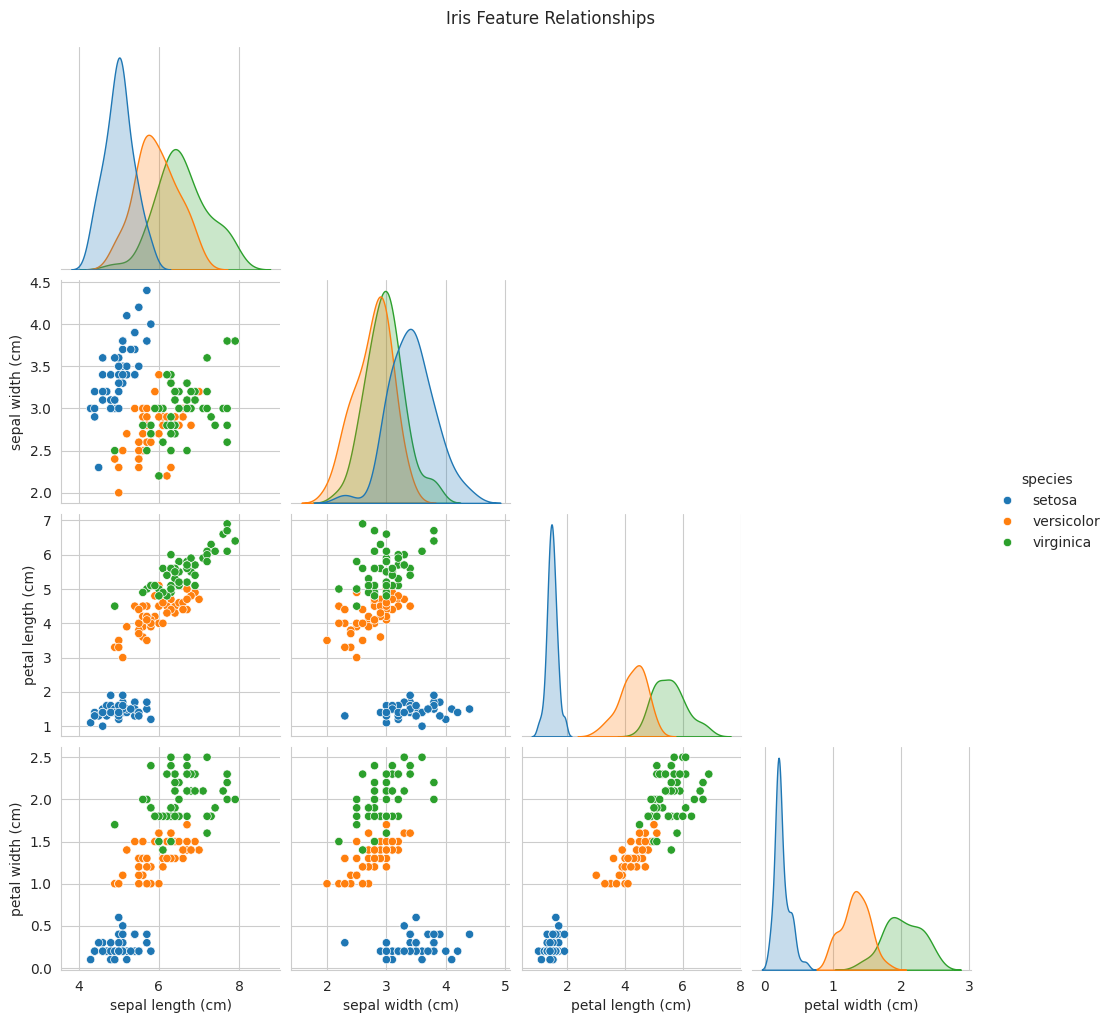

In [3]:
sns.pairplot(df, hue='species', corner=True)
plt.suptitle("Iris Feature Relationships", y=1.02)
plt.show()

## 3. The Intuition and Math Behind KNN

KNN classifies a new point based on the majority class among its **K nearest neighbors** in the training set.

### 3.1 Distance Metrics

**Euclidean Distance** (most common, straight-line distance):

$$
d(x, x_i) = \sqrt{\sum_{j=1}^{n}(x_j - x_{i,j})^2}
$$

**Manhattan Distance** (sum of absolute differences, useful for grid-like data):

$$
d(x, x_i) = \sum_{j=1}^{n}|x_j - x_{i,j}|
$$

### 3.2 The Algorithm

For a new point $x$:
1. Compute the distance between $x$ and every point in the training set.
2. Select the **K** closest points.
3. Take a **majority vote** among their class labels.
4. Assign that class to $x$.

### 3.3 Choosing K

- **Small K** (e.g. K=1): very flexible, low bias but high variance → can overfit and be sensitive to noise.
- **Large K**: smoother decision boundary, low variance but high bias → can underfit.
- K is usually chosen via cross-validation, and is often kept **odd** for binary classification to avoid ties.

## 4. Implementing KNN from Scratch

In [4]:
class KNNScratch:
    def __init__(self, k=5, distance_metric='euclidean'):
        self.k = k
        self.distance_metric = distance_metric

    def fit(self, X, y):
        # KNN is a "lazy learner" -- it just stores the training data
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        return self

    def _distance(self, x1, x2):
        if self.distance_metric == 'euclidean':
            return np.sqrt(np.sum((x1 - x2) ** 2))
        elif self.distance_metric == 'manhattan':
            return np.sum(np.abs(x1 - x2))
        else:
            raise ValueError("distance_metric must be 'euclidean' or 'manhattan'")

    def _predict_single(self, x):
        # Compute distance from x to every training point
        distances = [self._distance(x, x_train) for x_train in self.X_train]

        # Get indices of the k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = self.y_train[k_indices]

        # Majority vote
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]

    def predict(self, X):
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

## 5. Train / Test Split and Feature Scaling

KNN relies on distance calculations, so feature scaling is **essential** — features on larger scales would otherwise dominate the distance metric.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Train Our Scratch Model

In [6]:
model = KNNScratch(k=5, distance_metric='euclidean')
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Accuracy (Scratch Model, K=5):", accuracy_score(y_test, y_pred))

Accuracy (Scratch Model, K=5): 0.9333333333333333


## 7. Choosing the Best Value of K

Let's test a range of K values and see how accuracy changes, to find the sweet spot between bias and variance.

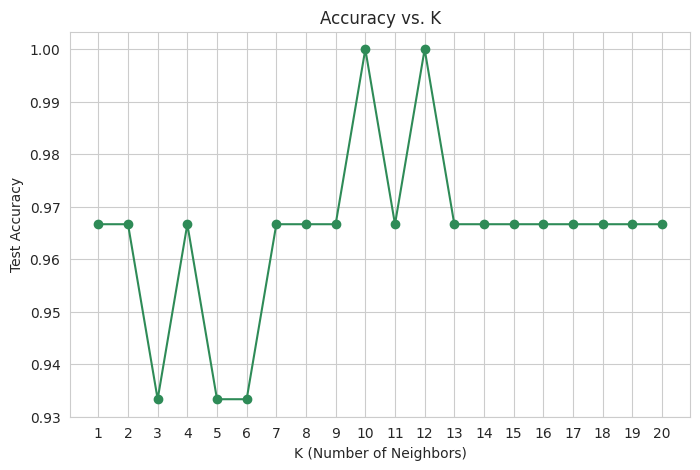

Best K: 10 with accuracy 1.0000


In [7]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNNScratch(k=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, preds))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', color='seagreen')
plt.title("Accuracy vs. K")
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.xticks(list(k_values))
plt.show()

best_k = k_values[int(np.argmax(accuracies))]
print(f"Best K: {best_k} with accuracy {max(accuracies):.4f}")

## 8. Model Evaluation (Using Best K)

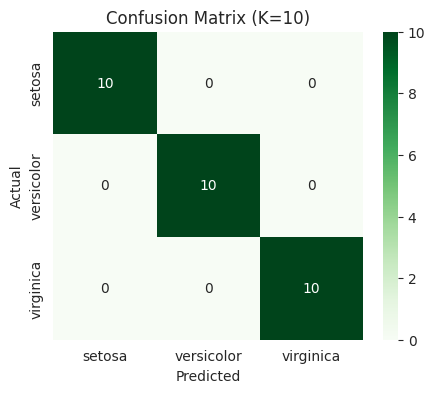

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [8]:
final_model = KNNScratch(k=best_k)
final_model.fit(X_train_scaled, y_train)
y_pred_final = final_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title(f"Confusion Matrix (K={best_k})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred_final, target_names=data.target_names))

## 9. Comparing with Scikit-learn's KNeighborsClassifier

Let's verify our from-scratch implementation against the industry-standard library.

In [9]:
from sklearn.neighbors import KNeighborsClassifier

sk_model = KNeighborsClassifier(n_neighbors=best_k)
sk_model.fit(X_train_scaled, y_train)
sk_pred = sk_model.predict(X_test_scaled)

print("Accuracy (Scratch Model):   ", accuracy_score(y_test, y_pred_final))
print("Accuracy (Scikit-learn):    ", accuracy_score(y_test, sk_pred))

cv_scores = cross_val_score(sk_model, StandardScaler().fit_transform(X), y, cv=5)
print("\nCross-validation accuracy (scikit-learn, 5-fold):", cv_scores.mean().round(4))

Accuracy (Scratch Model):    1.0
Accuracy (Scikit-learn):     0.9666666666666667

Cross-validation accuracy (scikit-learn, 5-fold): 0.96


## 10. Visualizing Decision Boundaries for Different K

To visualize decision boundaries, we use just 2 features (petal length & width).

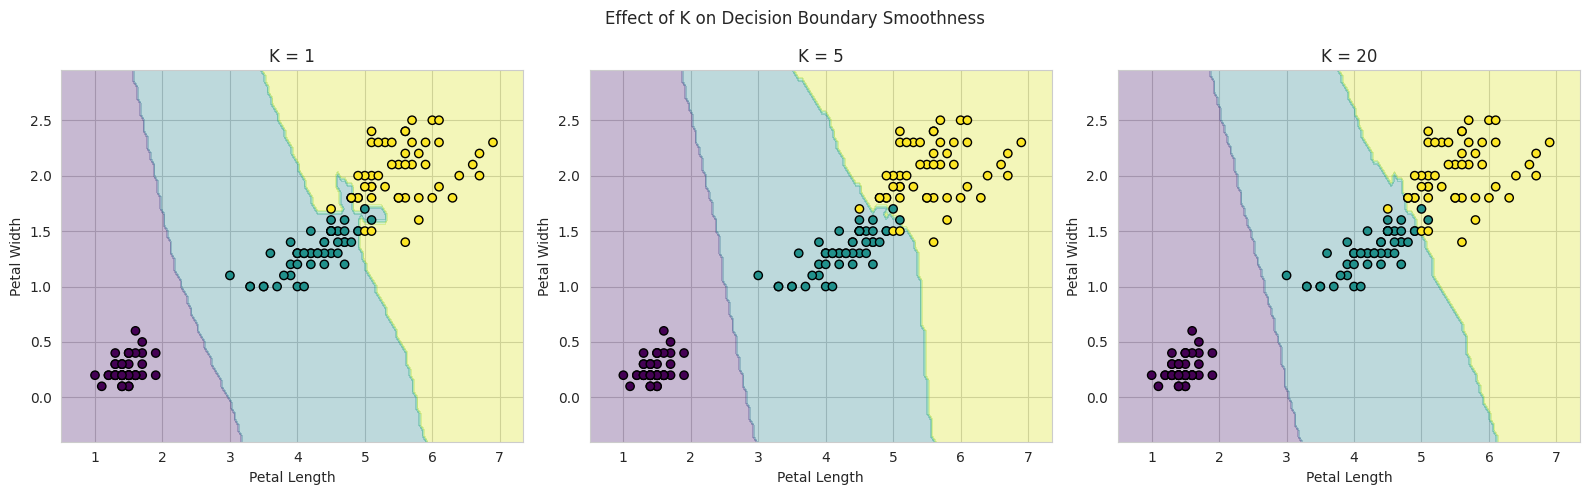

In [10]:
X2 = X[:, 2:4]  # petal length, petal width
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, k in zip(axes, [1, 5, 20]):
    knn2d = KNNScratch(k=k)
    knn2d.fit(X2_train, y2_train)

    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                          np.arange(y_min, y_max, 0.05))

    Z = knn2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap='viridis', edgecolors='k')
    ax.set_title(f"K = {k}")
    ax.set_xlabel("Petal Length")
    ax.set_ylabel("Petal Width")

plt.suptitle("Effect of K on Decision Boundary Smoothness")
plt.tight_layout()
plt.show()

## 📌 Key Takeaways

- KNN is a **lazy learner** — there's no real "training" phase, it just stores the data and computes distances at prediction time.
- Feature scaling is **critical** since KNN relies entirely on distance calculations.
- Small K → flexible, low bias, high variance (overfitting risk). Large K → smoother, high bias, low variance (underfitting risk).
- The best K is typically found through **cross-validation** or a simple accuracy-vs-K sweep like we did above.
- KNN can be slow on large datasets since it requires computing distances to *every* training point for each prediction — this is a key limitation compared to parametric models like Logistic Regression.

## 🔗 Next Steps
- Try weighting neighbors by distance (closer neighbors count more).
- Experiment with other distance metrics (Minkowski, Cosine similarity).
- Move on to **Decision Tree**, a model that learns explicit if-else rules instead of relying on distance.